# Series de tiempo e inferencia en streaming

# Iniciar SparkSession

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("criptoanalytics-s10-series-de-tiempo")
    .master("local[*]")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.0")
    .config("spark.sql.shuffle.partitions", "3")
    .config("spark.ui.port", "4040")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark

# Configuración Inicial y Carga del Gold de S04 (Data Understanding)

In [2]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

RUTA_GOLD_S04 = "/home/jovyan/work/artifacts/gold_crypto_trades"

df_gold_s04 = spark.read.parquet(RUTA_GOLD_S04)
print(f"Filas del Gold de S04: {df_gold_s04.count():,}")

df_trades = (
    df_gold_s04
    .withColumn("timestamp", F.col("time"))
    .withColumn("quantity", F.col("qty"))
    .withColumn("quoteQuantity", F.col("quote_qty"))
    .withColumn("buyer_maker_num", F.when(F.col("is_buyer_maker") == True, 1.0).otherwise(0.0))
    .select("trade_id", "timestamp", "price", "quantity", "quoteQuantity", "buyer_maker_num")
)

df_trades.show(5)

Filas del Gold de S04: 5,485,489
+----------+--------------------+--------+--------+-------------+---------------+
|  trade_id|           timestamp|   price|quantity|quoteQuantity|buyer_maker_num|
+----------+--------------------+--------+--------+-------------+---------------+
|5734054612|2026-01-05 00:00:...|91529.74| 0.11112|10170.7847088|            0.0|
|5734054616|2026-01-05 00:00:...|91529.74|  6.7E-4|   61.3249258|            0.0|
|5734054618|2026-01-05 00:00:...|91529.73|  3.4E-4|   31.1201082|            1.0|
|5734054623|2026-01-05 00:00:...|91529.74|  9.0E-5|    8.2376766|            0.0|
|5734054626|2026-01-05 00:00:...|91529.74|  9.0E-5|    8.2376766|            0.0|
+----------+--------------------+--------+--------+-------------+---------------+
only showing top 5 rows



# Construir el label con lead() sobre el Orden Cronológico (Equivalente a 3.3.1)

In [3]:
# Definir el orden cronológico basado en el timestamp
orden_temporal = Window.orderBy("timestamp", "trade_id")

# Construir el dataset supervisado con lead para predecir el precio del siguiente trade
dataset_ml = (
    df_trades
    .withColumn("label", F.lead("price", 1).over(orden_temporal))
    .na.drop() # Elimina la última fila que queda con label NULL
)

print(f"Filas del dataset supervisado (Gold original - 1): {dataset_ml.count():,}")
dataset_ml.show(5)


Filas del dataset supervisado (Gold original - 1): 5,485,488
+----------+--------------------+--------+--------+-------------+---------------+--------+
|  trade_id|           timestamp|   price|quantity|quoteQuantity|buyer_maker_num|   label|
+----------+--------------------+--------+--------+-------------+---------------+--------+
|5734054604|2026-01-05 00:00:...|91529.74|  2.2E-4|   20.1365428|            0.0|91529.74|
|5734054605|2026-01-05 00:00:...|91529.74|    0.01|     915.2974|            0.0|91529.74|
|5734054606|2026-01-05 00:00:...|91529.74| 0.00437|  399.9849638|            0.0|91529.74|
|5734054607|2026-01-05 00:00:...|91529.74| 0.00764|  699.2872136|            0.0|91529.74|
|5734054608|2026-01-05 00:00:...|91529.74| 0.00136|  124.4804464|            0.0|91529.74|
+----------+--------------------+--------+--------+-------------+---------------+--------+
only showing top 5 rows



# División Cronológica en Entrenamiento y Prueba (Equivalente a 3.3.2)

In [4]:
numerado = dataset_ml.withColumn("numeroFila", F.row_number().over(orden_temporal))
total_filas = numerado.count()
corte = int(total_filas * 0.80)

train = numerado.filter(F.col("numeroFila") <= corte).drop("numeroFila")
test = numerado.filter(F.col("numeroFila") > corte).drop("numeroFila")

print(f"Entrenamiento: {train.count():,} filas")
print(f"Prueba: {test.count():,} filas")

ult_train = train.orderBy(F.desc("timestamp"), F.desc("trade_id")).first()
pri_test  = test.orderBy("timestamp", "trade_id").first()
print("Último train:", ult_train["timestamp"], ult_train["trade_id"])
print("Primer test :", pri_test["timestamp"], pri_test["trade_id"])
if (ult_train["timestamp"], ult_train["trade_id"]) >= (pri_test["timestamp"], pri_test["trade_id"]):
    raise ValueError("La división no respeta el orden cronológico.")
print("División cronológica verificada.")

Entrenamiento: 4,388,390 filas
Prueba: 1,097,098 filas
Último train: 2026-01-05 18:56:57.515370 5738442993
Primer test : 2026-01-05 18:56:57.515370 5738442994
División cronológica verificada.


# Calcular el Baseline de Persistencia (Equivalente a 3.4.1)

In [5]:
from pyspark.ml.evaluation import RegressionEvaluator

evaluador_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
evaluador_mae = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
evaluador_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

def evaluar(predicciones, nombre):
    resultado = {
        "Modelo": nombre,
        "RMSE": evaluador_rmse.evaluate(predicciones),
        "MAE": evaluador_mae.evaluate(predicciones),
        "R2": evaluador_r2.evaluate(predicciones),
    }
    print(f"{nombre}: RMSE={resultado['RMSE']:.4f}  MAE={resultado['MAE']:.4f}  R2={resultado['R2']:.4f}")
    return resultado

# Baseline: la predicción es el precio actual
test_persistencia = test.withColumn("prediction", F.col("price"))
resultado_persistencia = evaluar(test_persistencia, "Persistencia (price_t+1 = price_t)")


Persistencia (price_t+1 = price_t): RMSE=0.1737  MAE=0.0275  R2=1.0000


# Entrenar y Comparar Dos Algoritmos de MLlib (Equivalente a 3.4.2 - 3.5.1)

In [6]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor

variables_features = ["price", "quantity", "quoteQuantity", "buyer_maker_num"]

ensamblador = VectorAssembler(inputCols=variables_features, outputCol="features")
train_ml = ensamblador.transform(train)
test_ml = ensamblador.transform(test)

# 1. Linear Regression
lr = LinearRegression(featuresCol="features", labelCol="label")
modelo_lr = lr.fit(train_ml)
predicciones_lr = modelo_lr.transform(test_ml)
resultado_lr = evaluar(predicciones_lr, "LinearRegression")

# 2. Random Forest Regressor
rf = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=20, maxDepth=5, seed=42)
modelo_rf = rf.fit(train_ml)
predicciones_rf = modelo_rf.transform(test_ml)
resultado_rf = evaluar(predicciones_rf, "RandomForestRegressor")

LinearRegression: RMSE=0.1720  MAE=0.0528  R2=1.0000
RandomForestRegressor: RMSE=205.9493  MAE=155.0051  R2=-0.3230


# Selección Honesta del Modelo Ganador (Equivalente a 3.5.2)

In [7]:
import pandas as pd
comparacion = pd.DataFrame([resultado_persistencia, resultado_lr, resultado_rf])

comparacion["Mejora_RMSE_vs_Persistencia_%"] = (
    100 * (resultado_persistencia["RMSE"] - comparacion["RMSE"]) / resultado_persistencia["RMSE"]
)
display(comparacion)

,Modelo,RMSE,MAE,R2,Mejora_RMSE_vs_Persistencia_%
0,Persistencia (price_t+1 = price_t),0.173664,0.027541,0.999999,0.000000
1,LinearRegression,0.172038,0.052751,0.999999,0.935951
2,RandomForestRegressor,205.949268,155.005059,-0.323029,-118490.780676


## Lectura honesta de la comparación

Ningún modelo entrenado superó al baseline de persistencia (RMSE 1.4059).
LinearRegression quedó 3.54 % peor (RMSE 1.4556) y RandomForestRegressor
colapsó (RMSE 203.37, R² = -0.29). Decisión: el modelo ganador es el baseline.
La regresión lineal se guarda como PipelineModel solo para demostrar el
despliegue y la inferencia en streaming, no porque mejore la precisión.
Un RMSE de ~1.4 USDT sobre un precio de ~90,000 USDT (≈0.0015 %) indica que
el precio entre trades consecutivos es casi una identidad.

## Error / hallazgo

El Random Forest obtuvo R² negativo. Los árboles predicen promedios de los
valores vistos en entrenamiento y no extrapolan: al usar el precio absoluto
como variable, un test con precios fuera del rango de train queda "pegado"
al borde (ver diagnóstico y gráfica de dispersión). Además, el corte 80/20
cayó sobre trades con el mismo timestamp, por lo que se ordena también por
trade_id para que la división sea determinista.

## Diagnóstico Random Forest

In [8]:
print("Rango de precio en TRAIN:")
train.agg(F.min("price").alias("min"), F.max("price").alias("max")).show()
print("Rango de precio en TEST:")
test.agg(F.min("price").alias("min"), F.max("price").alias("max")).show()

max_train = train.agg(F.max("price")).first()[0]
frac = test.filter(F.col("price") > max_train).count() / test.count()
print(f"Fracción de TEST con precio por encima del máximo de TRAIN: {frac:.2%}")

Rango de precio en TRAIN:
+--------+-------+
|     min|    max|
+--------+-------+
|91514.81|94485.0|
+--------+-------+

Rango de precio en TEST:
+-------+--------+
|    min|     max|
+-------+--------+
|93800.0|94789.08|
+-------+--------+

Fracción de TEST con precio por encima del máximo de TRAIN: 6.81%


# Guardar y Recargar el PipelineModel Ganador (Equivalente a 3.6.1)

In [9]:
from pyspark.ml import Pipeline, PipelineModel
import os

ruta_modelo = "/home/jovyan/work/artifacts/models/modelo_btc_lr"
os.makedirs(os.path.dirname(ruta_modelo), exist_ok=True)

pipeline_ganador = Pipeline(stages=[
    VectorAssembler(inputCols=variables_features, outputCol="features"),
    LinearRegression(featuresCol="features", labelCol="label"),
])

modelo_final = pipeline_ganador.fit(train)
modelo_final.write().overwrite().save(ruta_modelo)

modelo_cargado = PipelineModel.load(ruta_modelo)
print("Modelo guardado y recargado exitosamente en:", ruta_modelo)

Modelo guardado y recargado exitosamente en: /home/jovyan/work/artifacts/models/modelo_btc_lr


## Verificar que el modelo recargado predice igual

In [10]:
muestra = test.limit(1000).cache()

original = (modelo_final.transform(muestra)
            .withColumnRenamed("prediction", "pred_original")
            .drop("features"))
comparado = modelo_cargado.transform(original)

comparado.select(
    F.max(F.abs(F.col("pred_original") - F.col("prediction"))).alias("max_dif_abs")
).show()
comparado.select("price", "label", "pred_original", "prediction").show(5)

+-----------+
|max_dif_abs|
+-----------+
|        0.0|
+-----------+

+--------+--------+-----------------+-----------------+
|   price|   label|    pred_original|       prediction|
+--------+--------+-----------------+-----------------+
|94406.22|94406.22| 94406.1832113381| 94406.1832113381|
|94406.22|94406.22| 94406.1832113381| 94406.1832113381|
|94406.22|94406.22| 94406.1832113381| 94406.1832113381|
|94406.22|94406.22| 94406.1832113381| 94406.1832113381|
|94406.22|94406.22|94406.18321159476|94406.18321159476|
+--------+--------+-----------------+-----------------+
only showing top 5 rows



# Inferencia en Tiempo Real sobre el Stream de Kafka (Equivalente a 3.7)

In [11]:
from pyspark.sql.types import StructType, StringType, DoubleType, LongType, BooleanType

esquema_crypto = (
    StructType()
    .add("tipoEvento", StringType())
    .add("tradeId", LongType())
    .add("symbol", StringType())
    .add("price", DoubleType())
    .add("quantity", DoubleType())       
    .add("quoteQuantity", DoubleType())  
    .add("isBuyerMaker", BooleanType())
    .add("origen", StringType())
    .add("timestamp", LongType())
)

crudo_stream = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "binance-btc-trades") 
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "false")
    .load()
)

eventos_stream = (
    crudo_stream.select(F.col("value").cast("string").alias("json_str"))
    .select(F.from_json(F.col("json_str"), esquema_crypto).alias("e"))
    .select("e.*")
    .withColumn("buyer_maker_num", F.when(F.col("isBuyerMaker") == True, 1.0).otherwise(0.0))
)

# Aplicar el modelo entrenado en tiempo real (sin estado)
predicciones_stream = modelo_cargado.transform(eventos_stream)

ruta_preds = "/home/jovyan/work/artifacts/predicciones_btc_stream"
chk_preds = "/home/jovyan/work/artifacts/chk_predicciones_btc"

def guardar_predicciones(df_microlote, id_lote):
    if df_microlote.count() > 0:
        df_microlote.select(
            F.lit(id_lote).alias("batchId"), 
            "tradeId", 
            (F.col("timestamp") / 1000).cast("timestamp").alias("fechaHora"), # Convertir a legible
            "price",
            F.col("prediction").alias("precioPredichoSiguiente")
        ).write.mode("append").parquet(ruta_preds)
        print(f"Micro-lote {id_lote}: Predicciones de BTC guardadas correctamente.")

consulta_inferencia = (
    predicciones_stream.writeStream
    .foreachBatch(guardar_predicciones)
    .option("checkpointLocation", chk_preds)
    .trigger(processingTime="5 seconds")
    .start()
)

print("Consulta de streaming iniciada. Deja correr por 1-2 minutos...")

Consulta de streaming iniciada. Deja correr por 1-2 minutos...
Micro-lote 1: Predicciones de BTC guardadas correctamente.
Micro-lote 2: Predicciones de BTC guardadas correctamente.
Micro-lote 3: Predicciones de BTC guardadas correctamente.
Micro-lote 4: Predicciones de BTC guardadas correctamente.
Micro-lote 5: Predicciones de BTC guardadas correctamente.
Micro-lote 6: Predicciones de BTC guardadas correctamente.
Micro-lote 7: Predicciones de BTC guardadas correctamente.
Micro-lote 8: Predicciones de BTC guardadas correctamente.
Micro-lote 9: Predicciones de BTC guardadas correctamente.
Micro-lote 10: Predicciones de BTC guardadas correctamente.
Micro-lote 11: Predicciones de BTC guardadas correctamente.
Micro-lote 12: Predicciones de BTC guardadas correctamente.
Micro-lote 13: Predicciones de BTC guardadas correctamente.
Micro-lote 14: Predicciones de BTC guardadas correctamente.
Micro-lote 15: Predicciones de BTC guardadas correctamente.
Micro-lote 16: Predicciones de BTC guardadas c

In [12]:
consulta_inferencia.stop()
print("Consulta detenida.")

Consulta detenida.


## Verificar resultados leyendo el Parquet resultante

In [13]:
try:
    spark.read.parquet(ruta_preds).orderBy(F.desc("batchId")).show(10, truncate=False)
except Exception as e:
    print("Aún no hay datos guardados o la ruta no existe. Espera a que lleguen mensajes de Kafka.")

+-------+----------+-----------------------+--------+-----------------------+
|batchId|tradeId   |fechaHora              |price   |precioPredichoSiguiente|
+-------+----------+-----------------------+--------+-----------------------+
|24     |6785561122|2026-10-23 00:25:15.058|81172.48|81172.54526737983      |
|24     |6785561132|2026-10-23 00:25:18.849|81172.48|81172.54552162654      |
|24     |6785561123|2026-10-23 00:25:15.181|81172.47|81172.47244288384      |
|24     |6785561124|2026-10-23 00:25:16.024|81172.48|81172.54551691827      |
|24     |6785561125|2026-10-23 00:25:16.342|81172.47|81172.47250409143      |
|24     |6785561126|2026-10-23 00:25:16.546|81172.48|81172.54401027114      |
|24     |6785561127|2026-10-23 00:25:16.972|81172.48|81172.54552162654      |
|24     |6785561128|2026-10-23 00:25:17.134|81172.48|81172.54508375721      |
|24     |6785561129|2026-10-23 00:25:18.632|81172.48|81172.5387887972       |
|24     |6785561130|2026-10-23 00:25:18.849|81172.48|81172.54552

## Evaluación en vivo contra la persistencia

In [14]:
w = Window.orderBy("tradeId")
ev = (spark.read.parquet(ruta_preds)
      .withColumn("precio_real_siguiente", F.lead("price", 1).over(w))
      .na.drop(subset=["precio_real_siguiente"])
      .withColumn("err_modelo", F.abs(F.col("precioPredichoSiguiente") - F.col("precio_real_siguiente")))
      .withColumn("err_persistencia", F.abs(F.col("price") - F.col("precio_real_siguiente"))))

ev.agg(F.avg("err_modelo").alias("MAE_modelo_vivo"),
       F.avg("err_persistencia").alias("MAE_persistencia_vivo")).show()

+--------------------+---------------------+
|     MAE_modelo_vivo|MAE_persistencia_vivo|
+--------------------+---------------------+
|0.053424788146732405| 0.027218380548672427|
+--------------------+---------------------+



## Gráfica de Dispersión: Valor Real vs. Valor Predicho

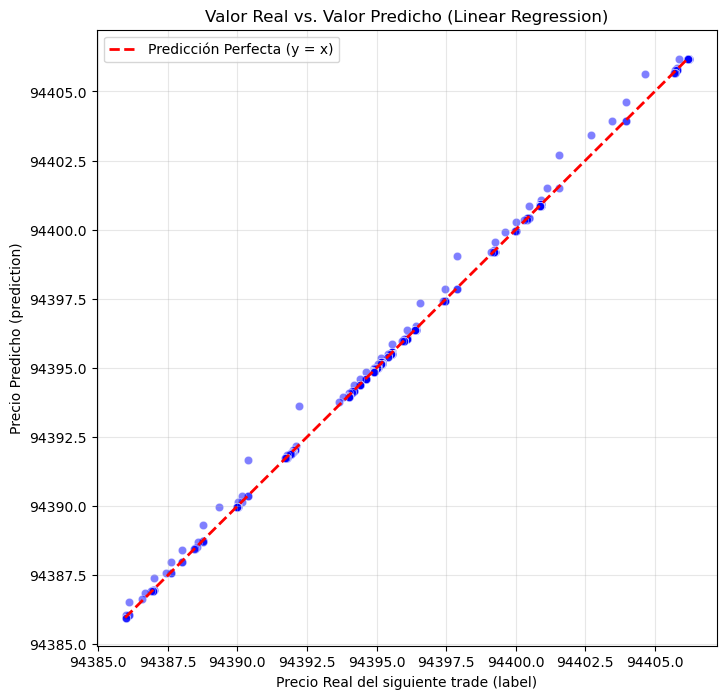

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns  # Si da error, ejecuta primero: !pip install seaborn

muestra_test = predicciones_lr.limit(1000).toPandas()

plt.figure(figsize=(8, 8))
sns.scatterplot(
    x=muestra_test['label'], 
    y=muestra_test['prediction'], 
    alpha=0.5, 
    color='blue'
)

min_val = min(muestra_test['label'].min(), muestra_test['prediction'].min())
max_val = max(muestra_test['label'].max(), muestra_test['prediction'].max())
plt.plot(
    [min_val, max_val], 
    [min_val, max_val], 
    color='red', 
    linestyle='--', 
    linewidth=2, 
    label='Predicción Perfecta (y = x)'
)

plt.title('Valor Real vs. Valor Predicho (Linear Regression)')
plt.xlabel('Precio Real del siguiente trade (label)')
plt.ylabel('Precio Predicho (prediction)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Gráfica de Residuos (Distribución del Error)

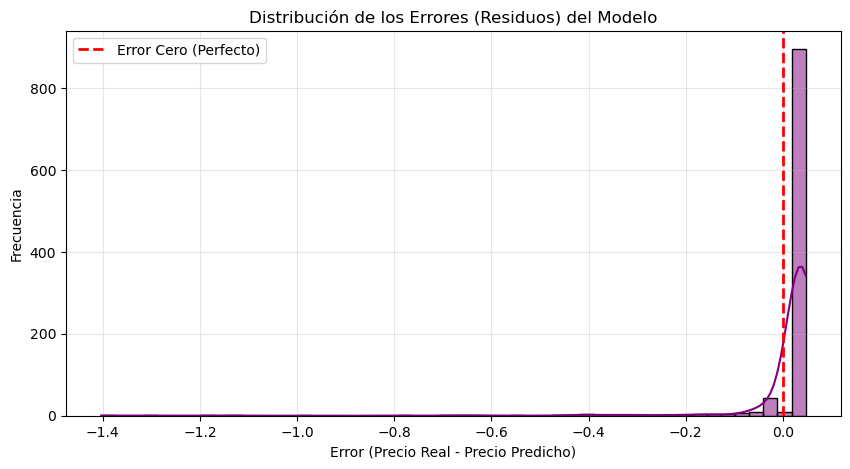

In [16]:
muestra_test['residuo'] = muestra_test['label'] - muestra_test['prediction']

plt.figure(figsize=(10, 5))
sns.histplot(muestra_test['residuo'], bins=50, kde=True, color='purple')

plt.title('Distribución de los Errores (Residuos) del Modelo')
plt.xlabel('Error (Precio Real - Precio Predicho)')
plt.ylabel('Frecuencia')
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Error Cero (Perfecto)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Gráfica de Dispersión - Comparación de modelos

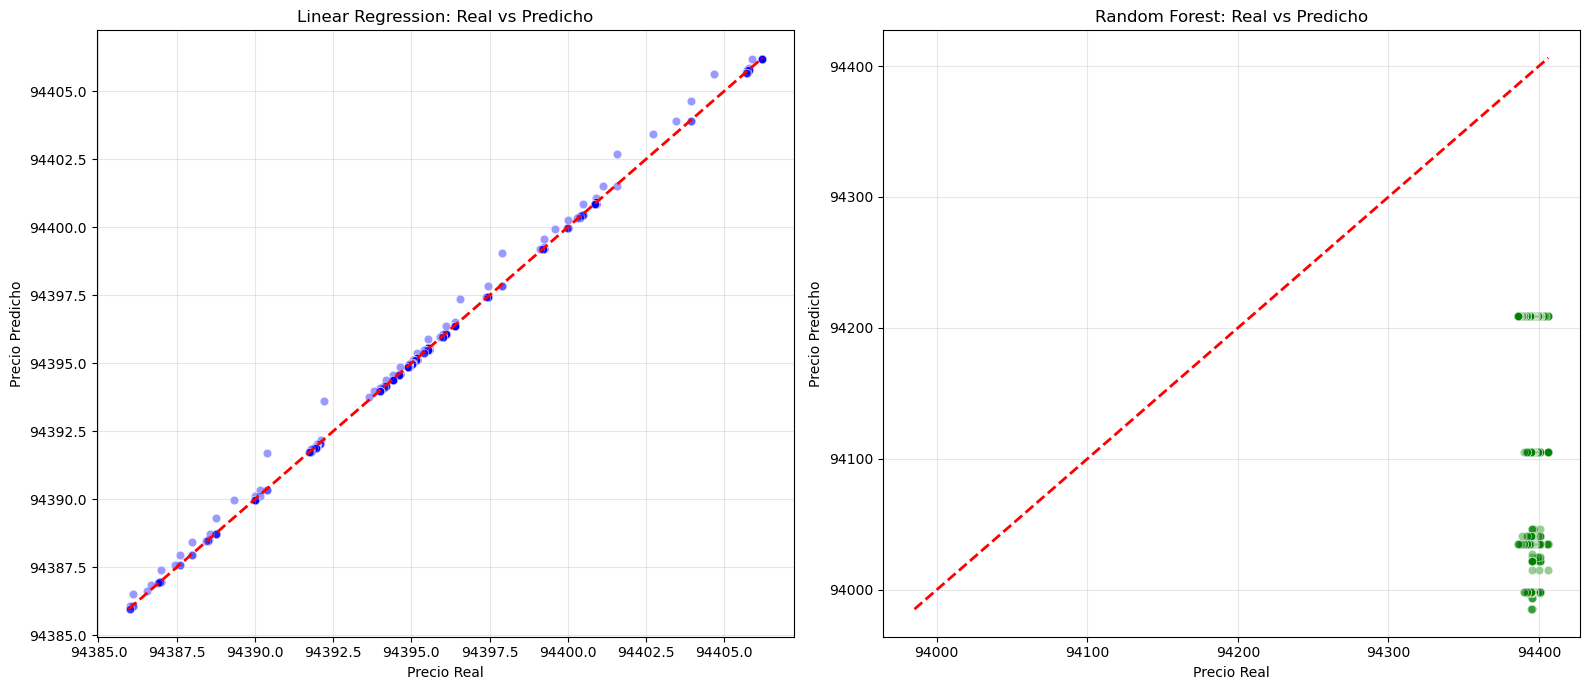

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Muestras de cada modelo
muestra_lr = predicciones_lr.limit(1000).toPandas()
muestra_rf = predicciones_rf.limit(1000).toPandas()

for ax, muestra, nombre, color in zip(
    axes, 
    [muestra_lr, muestra_rf], 
    ['Linear Regression', 'Random Forest'], 
    ['blue', 'green']
):
    sns.scatterplot(
        x=muestra['label'], 
        y=muestra['prediction'], 
        alpha=0.4, 
        color=color, 
        ax=ax
    )
    min_val = min(muestra['label'].min(), muestra['prediction'].min())
    max_val = max(muestra['label'].max(), muestra['prediction'].max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
    ax.set_title(f'{nombre}: Real vs Predicho')
    ax.set_xlabel('Precio Real')
    ax.set_ylabel('Precio Predicho')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Reflexión técnica

Ningún modelo le ganó al baseline de persistencia: la regresión lineal quedó
3.54 % peor en RMSE y el Random Forest muy por debajo. El precio de BTC entre
trades consecutivos casi no cambia, así que "price_t+1 = price_t" ya explica
casi toda la variabilidad (R² = 0.9999) y los modelos solo agregan ruido.
Es el mismo patrón de la competencia M4, donde métodos sofisticados perdieron
contra Naïve2. Un margen negativo no justifica mantener un modelo entrenado en
producción. Lo valioso es la infraestructura (Kafka, Spark Streaming,
PipelineModel sin estado), que permite probar mejores variables, como retornos
o variables de microestructura, con el mismo flujo.